# Clustering Mini Project — Country Data

Dataset: https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data

## Data Preparation

In [ ]:
# Importing the libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
# Loading the data
import kagglehub
import os
path = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")
print("Path to dataset files:", path)
print("Files:", os.listdir(path))

df = pd.read_csv(os.path.join(path, "Country-data.csv"))
df.head()

Using Colab cache for faster access to the 'unsupervised-learning-on-country-data' dataset.
Path to dataset files: /kaggle/input/unsupervised-learning-on-country-data
Files: ['Country-data.csv', 'data-dictionary.csv']


,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [ ]:
# The size of the data
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print(df.columns.tolist())

Number of rows: 167
Number of columns: 10
['country', 'child_mort', 'exports', 'health', 'imports', 'income', 'inflation', 'life_expec', 'total_fer', 'gdpp']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB


In [ ]:
# Checking for missing values
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())

country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64

Total missing values: 0


In [ ]:
# Separating the features
country_names = df["country"]
X = df.drop("country", axis=1)
X.head()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [ ]:
X.describe()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
count,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000,167.000000
mean,38.270060,41.108976,6.815689,46.890215,17144.688623,7.781832,70.555689,2.947964,12964.155689
std,40.328931,27.412010,2.746837,24.209589,19278.067698,10.570704,8.893172,1.513848,18328.704809
min,2.600000,0.109000,1.810000,0.065900,609.000000,-4.210000,32.100000,1.150000,231.000000
25%,8.250000,23.800000,4.920000,30.200000,3355.000000,1.810000,65.300000,1.795000,1330.000000
50%,19.300000,35.000000,6.320000,43.300000,9960.000000,5.390000,73.100000,2.410000,4660.000000
75%,62.100000,51.350000,8.600000,58.750000,22800.000000,10.750000,76.800000,3.880000,14050.000000
max,208.000000,200.000000,17.900000,174.000000,125000.000000,104.000000,82.800000,7.490000,105000.000000


In [ ]:
# Scaling
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns)
X_scaled.head()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,1.291532,-1.138280,0.279088,-0.082455,-0.808245,0.157336,-1.619092,1.902882,-0.679180
1,-0.538949,-0.479658,-0.097016,0.070837,-0.375369,-0.312347,0.647866,-0.859973,-0.485623
2,-0.272833,-0.099122,-0.966073,-0.641762,-0.220844,0.789274,0.670423,-0.038404,-0.465376
3,2.007808,0.775381,-1.448071,-0.165315,-0.585043,1.387054,-1.179234,2.128151,-0.516268
4,-0.695634,0.160668,-0.286894,0.497568,0.101732,-0.601749,0.704258,-0.541946,-0.041817


## K-Means (Before PCA)

In [ ]:
# The Elbow Method
k_values = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
inertia_values = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)
    print("K =", k, "-> inertia =", round(model.inertia_, 2))

K = 1 -> inertia = 1503.0
K = 2 -> inertia = 1050.21
K = 3 -> inertia = 831.42
K = 4 -> inertia = 700.52
K = 5 -> inertia = 620.16
K = 6 -> inertia = 558.47
K = 7 -> inertia = 495.81
K = 8 -> inertia = 457.59
K = 9 -> inertia = 427.8
K = 10 -> inertia = 403.23


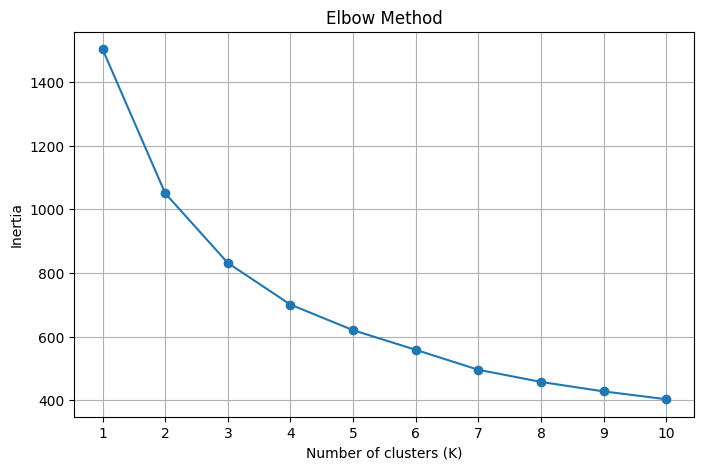

In [ ]:
# Elbow chart
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [ ]:
k_values_2 = [2, 3, 4, 5, 6, 7, 8, 9, 10]
silhouette_values = []

for k in k_values_2:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)
    print("K =", k, "-> silhouette score =", round(score, 4))

K = 2 -> silhouette score = 0.2874
K = 3 -> silhouette score = 0.2833
K = 4 -> silhouette score = 0.296
K = 5 -> silhouette score = 0.2993
K = 6 -> silhouette score = 0.2287
K = 7 -> silhouette score = 0.2477
K = 8 -> silhouette score = 0.2388
K = 9 -> silhouette score = 0.2073
K = 10 -> silhouette score = 0.2022


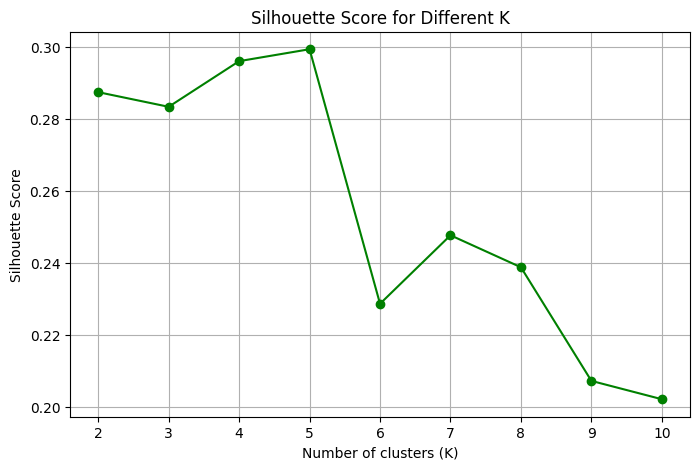

In [ ]:
# Silhouette chart
plt.figure(figsize=(8, 5))
plt.plot(k_values_2, silhouette_values, marker="o", color="green")
plt.title("Silhouette Score for Different K")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values_2)
plt.grid(True)
plt.show()

In [ ]:
best_k = 3

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Number of clusters:", best_k)
print(kmeans_labels[:20])

Number of clusters: 3
[1 2 2 1 2 2 2 0 0 2 2 0 2 2 2 0 2 1 2 2]


In [ ]:
df["KMeans_Cluster"] = kmeans_labels
df.head(10)

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,KMeans_Cluster
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.440,56.2,5.82,553,1
1,Albania,16.6,28.0,6.55,48.6,9930,4.490,76.3,1.65,4090,2
2,Algeria,27.3,38.4,4.17,31.4,12900,16.100,76.5,2.89,4460,2
3,Angola,119.0,62.3,2.85,42.9,5900,22.400,60.1,6.16,3530,1
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.440,76.8,2.13,12200,2
5,Argentina,14.5,18.9,8.10,16.0,18700,20.900,75.8,2.37,10300,2
6,Armenia,18.1,20.8,4.40,45.3,6700,7.770,73.3,1.69,3220,2
7,Australia,4.8,19.8,8.73,20.9,41400,1.160,82.0,1.93,51900,0
8,Austria,4.3,51.3,11.00,47.8,43200,0.873,80.5,1.44,46900,0
9,Azerbaijan,39.2,54.3,5.88,20.7,16000,13.800,69.1,1.92,5840,2


In [ ]:
print(df["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0    36
1    47
2    84
Name: count, dtype: int64


In [ ]:
kmeans_score = silhouette_score(X_scaled, kmeans_labels)
print("Silhouette Score for K-Means before PCA:", round(kmeans_score, 4))

Silhouette Score for K-Means before PCA: 0.2833


In [ ]:
cluster_summary = df.groupby("KMeans_Cluster").mean(numeric_only=True)
cluster_summary.round(2)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
KMeans_Cluster,,,,,,,,,
0,5.00,58.74,8.81,51.49,45672.22,2.67,80.13,1.75,42494.44
1,92.96,29.15,6.39,42.32,3942.40,12.02,59.19,5.01,1922.38
2,21.93,40.24,6.20,47.47,12305.60,7.60,72.81,2.31,6486.45


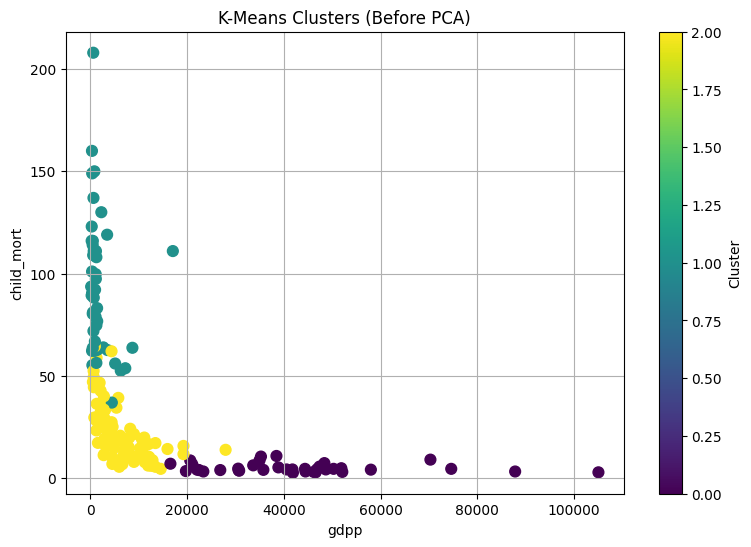

In [ ]:
plt.figure(figsize=(9, 6))
plt.scatter(df["gdpp"], df["child_mort"], c=df["KMeans_Cluster"], cmap="viridis", s=60)
plt.title("K-Means Clusters (Before PCA)")
plt.xlabel("gdpp")
plt.ylabel("child_mort")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

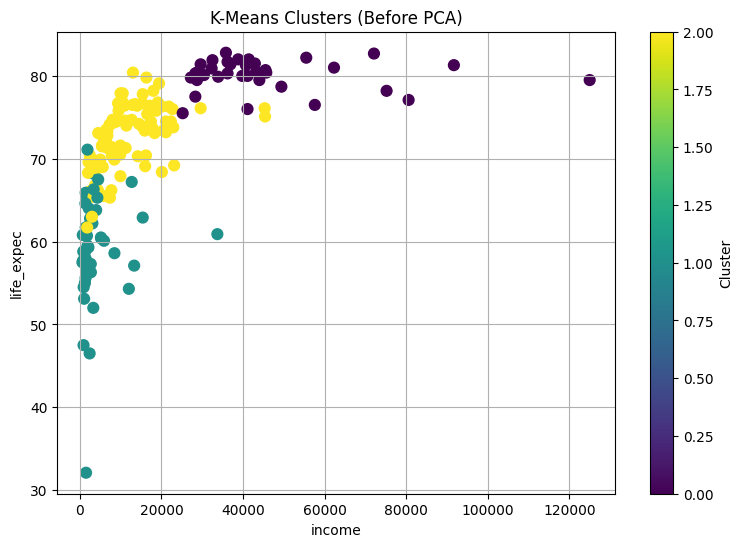

In [ ]:
plt.figure(figsize=(9, 6))
plt.scatter(df["income"], df["life_expec"], c=df["KMeans_Cluster"], cmap="viridis", s=60)
plt.title("K-Means Clusters (Before PCA)")
plt.xlabel("income")
plt.ylabel("life_expec")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()

In [ ]:
for cluster_number in range(best_k):
    countries_in_cluster = df[df["KMeans_Cluster"] == cluster_number]["country"]
    print("Cluster", cluster_number, "-", len(countries_in_cluster), "countries")
    print(countries_in_cluster.head(10).tolist())
    print()

Cluster 0 - 36 countries
['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Czech Republic', 'Denmark', 'Finland']

Cluster 1 - 47 countries
['Afghanistan', 'Angola', 'Benin', 'Botswana', 'Burkina Faso', 'Burundi', 'Cameroon', 'Central African Republic', 'Chad', 'Comoros']

Cluster 2 - 84 countries
['Albania', 'Algeria', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Azerbaijan', 'Bahamas', 'Bangladesh', 'Barbados', 'Belarus']



## DBSCAN (Before PCA)

DBSCAN groups points that are packed close together.

- **eps**: the radius of the circle around each point.
- **min_samples**: how many points (including the point itself) must be inside that circle for it to count as a dense area.
- Points that are not in any dense area get the label **-1** = noise (outliers).

In [ ]:
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

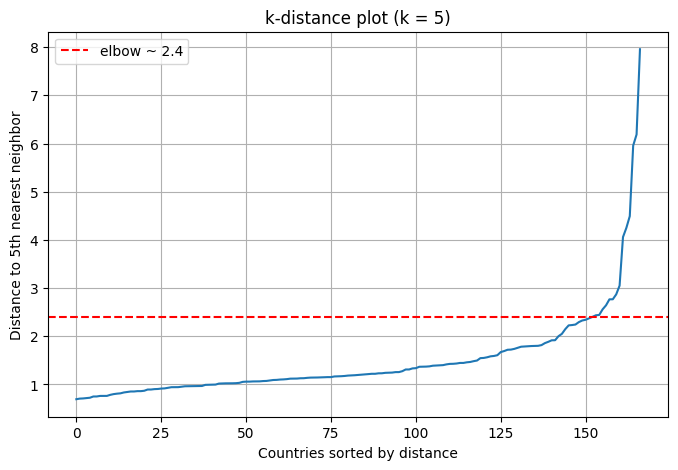

In [ ]:
neighbors = NearestNeighbors(n_neighbors=5)
neighbors.fit(X_scaled)
distances, indices = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.axhline(2.4, color="red", linestyle="--", label="elbow ~ 2.4")
plt.title("k-distance plot (k = 5)")
plt.xlabel("Countries sorted by distance")
plt.ylabel("Distance to 5th nearest neighbor")
plt.legend()
plt.grid(True)
plt.show()

DBSCAN with eps = 2.4. Gives 1 cluster + 8 outliers.

In [ ]:
dbscan_elbow = DBSCAN(eps=2.4, min_samples=5)
elbow_labels = dbscan_elbow.fit_predict(X_scaled)

print("Clusters found:", len(set(elbow_labels)) - (1 if -1 in elbow_labels else 0))
print("Noise points:", (elbow_labels == -1).sum())
print(df[elbow_labels == -1]["country"].tolist())

Clusters found: 1
Noise points: 8
['Haiti', 'Luxembourg', 'Malta', 'Nigeria', 'Qatar', 'Singapore', 'United States', 'Venezuela']


Tunning the esp and minsamples to find the best

In [ ]:
eps_values = [0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.8, 2.0, 2.2, 2.4]
min_samples_values = [3, 4, 5, 6, 8, 10]
results = []

for ms in min_samples_values:
    for eps in eps_values:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()

        if n_clusters >= 2:
            mask = labels != -1
            score = silhouette_score(X_scaled[mask], labels[mask])
        else:
            score = None

        results.append({"eps": eps, "min_samples": ms, "clusters": n_clusters,
                        "noise": n_noise, "noise %": round(n_noise / len(X_scaled) * 100, 1),
                        "silhouette": score})

results_df = pd.DataFrame(results)
results_df[results_df["clusters"] >= 2].round(3)

,eps,min_samples,clusters,noise,noise %,silhouette
0,0.8,3,8,112,67.1,0.245
1,0.9,3,4,100,59.9,0.260
2,1.0,3,6,72,43.1,0.309
3,1.1,3,4,58,34.7,0.346
4,1.2,3,4,41,24.6,0.298
5,1.3,3,2,37,22.2,0.053
7,1.5,3,2,25,15.0,0.226
8,1.6,3,2,23,13.8,0.221
9,1.8,3,2,16,9.6,0.207
13,0.8,4,5,134,80.2,0.363


eps=1.3, min_samples=6: highest silhouette with 2+ clusters and noise under 30%

In [ ]:
# Final DBSCAN model
dbscan = DBSCAN(eps=1.3, min_samples=6)
dbscan_labels = dbscan.fit_predict(X_scaled)

df["DBSCAN_Cluster"] = dbscan_labels
print(df["DBSCAN_Cluster"].value_counts().sort_index())

DBSCAN_Cluster
-1    48
 0    24
 1    95
Name: count, dtype: int64


In [ ]:
mask = dbscan_labels != -1
dbscan_score = silhouette_score(X_scaled[mask], dbscan_labels[mask])

print("DBSCAN silhouette (without noise):", round(dbscan_score, 4))
print("Countries used:", mask.sum(), "out of", len(df))
print("K-Means silhouette:", round(kmeans_score, 4))

DBSCAN silhouette (without noise): 0.4131
Countries used: 119 out of 167
K-Means silhouette: 0.2833


In [ ]:
df.groupby("DBSCAN_Cluster").mean(numeric_only=True).drop(columns=["KMeans_Cluster"]).round(2)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
DBSCAN_Cluster,,,,,,,,,
-1,51.62,53.29,6.83,55.10,24397.85,13.15,67.90,3.36,17542.85
0,94.12,23.73,5.75,38.62,1858.58,7.54,59.08,5.38,753.04
1,17.41,39.35,7.08,44.83,17341.68,5.13,74.80,2.13,13735.62


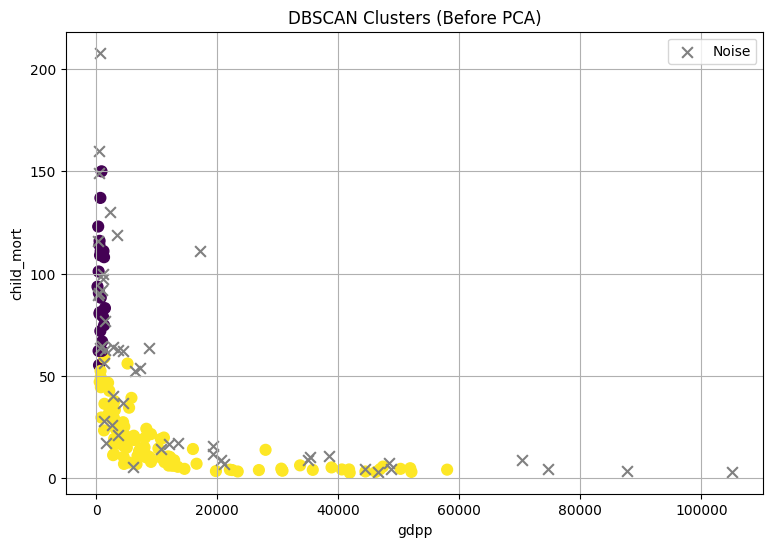

In [ ]:
noise = df["DBSCAN_Cluster"] == -1

plt.figure(figsize=(9, 6))
plt.scatter(df[~noise]["gdpp"], df[~noise]["child_mort"], c=df[~noise]["DBSCAN_Cluster"], cmap="viridis", s=60)
plt.scatter(df[noise]["gdpp"], df[noise]["child_mort"], c="gray", marker="x", s=60, label="Noise")
plt.title("DBSCAN Clusters (Before PCA)")
plt.xlabel("gdpp")
plt.ylabel("child_mort")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
for c in sorted(df["DBSCAN_Cluster"].unique()):
    names = df[df["DBSCAN_Cluster"] == c]["country"].tolist()
    print("Noise" if c == -1 else f"Cluster {c}", "-", len(names), "countries")
    print(names)
    print()

Noise - 48 countries
['Angola', 'Bahrain', 'Belarus', 'Belgium', 'Botswana', 'Brunei', 'Central African Republic', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Equatorial Guinea', 'Gabon', 'Haiti', 'Iraq', 'Ireland', 'Jordan', 'Kiribati', 'Kuwait', 'Lesotho', 'Liberia', 'Libya', 'Luxembourg', 'Malta', 'Mauritania', 'Micronesia, Fed. Sts.', 'Moldova', 'Mongolia', 'Myanmar', 'Nigeria', 'Norway', 'Oman', 'Pakistan', 'Qatar', 'Rwanda', 'Saudi Arabia', 'Seychelles', 'Sierra Leone', 'Singapore', 'Solomon Islands', 'South Africa', 'Sudan', 'Switzerland', 'Timor-Leste', 'Togo', 'Turkmenistan', 'United Arab Emirates', 'United States', 'Venezuela', 'Yemen']

Cluster 0 - 24 countries
['Afghanistan', 'Benin', 'Burkina Faso', 'Burundi', 'Cameroon', 'Chad', 'Comoros', "Cote d'Ivoire", 'Eritrea', 'Gambia', 'Ghana', 'Guinea', 'Guinea-Bissau', 'Kenya', 'Lao', 'Madagascar', 'Malawi', 'Mali', 'Mozambique', 'Niger', 'Senegal', 'Tanzania', 'Uganda', 'Zambia']

Cluster 1 - 95 countries
['Albania', 'Algeria', 'Antigu

In [ ]:
pd.crosstab(df["DBSCAN_Cluster"], df["KMeans_Cluster"], rownames=["DBSCAN"], colnames=["K-Means"])

K-Means,0,1,2
DBSCAN,,,
-1,13,22,13
0,0,24,0
1,23,1,71


### DBSCAN Findings

**Best settings:** eps = 1.3, min_samples = 6 (highest silhouette with at least 2 clusters and noise under 30%).

**Results:**
- **Cluster 0 (24 countries):** the poorest countries, with high child mortality (about 94), very low income (about 1,860) and low life expectancy (about 59). Examples: Afghanistan, Chad, Niger, Mali.
- **Cluster 1 (95 countries):** rich and middle-income countries together, with low child mortality (about 17) and higher income (about 17,300).
- **Noise (48 countries, 28.7%):** extreme countries at both ends, very rich ones (Luxembourg, Norway, Switzerland, Qatar) and very poor ones (Nigeria, Haiti, Central African Republic).

**Silhouette score:** 0.4131 (without noise) vs 0.2833 for K-Means. This is **not a fair comparison**, because DBSCAN removed the 48 hardest countries, while K-Means had to place all 167.

**What we found out:**
- With the eps from the k-distance plot (2.4), DBSCAN found only **1 cluster + 8 outliers**. This means the countries do not form separate groups with clear gaps between them. They change gradually from poor to rich.
- To get more than 1 cluster, we had to use a smaller eps, which made almost 29% of the countries noise.
- DBSCAN **merged K-Means clusters 0 and 2** (rich and middle) into one cluster, because there is no empty space between them.
- The density is uneven: rich countries are spread out, while middle-income countries are packed close together. One eps value cannot fit both.

**Conclusion:** DBSCAN is not the best choice for clustering this dataset, but it is useful for **detecting outliers**. It found the extreme countries that K-Means was forced to put into a cluster.

## Hierarchical Clustering (Before PCA)
**How it works:**
1. Start with every country as its own cluster (167 clusters).
2. Merge the two **closest** clusters.
3. Repeat until everything is one cluster.

Every merge and the distance it happened at is recorded and drawn as a **dendrogram**. The height of each joint is how far apart the merged groups were. To get *k* clusters, we **cut the tree** at a height that leaves *k* branches, so unlike K-Means, we don't have to choose k in advance.

**Linkage method:** how the distance between two *groups* is measured:

| Linkage | Distance between two clusters = | Tends to produce |
|---|---|---|
| Single | closest pair of points | chains; one giant cluster plus tiny outlier clusters |
| Complete | farthest pair of points | compact clusters, sensitive to outliers |
| Average | average over all pairs | a middle ground |
| Ward | increase in within-cluster variance after merging | compact, balanced clusters (similar to K-Means) |

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

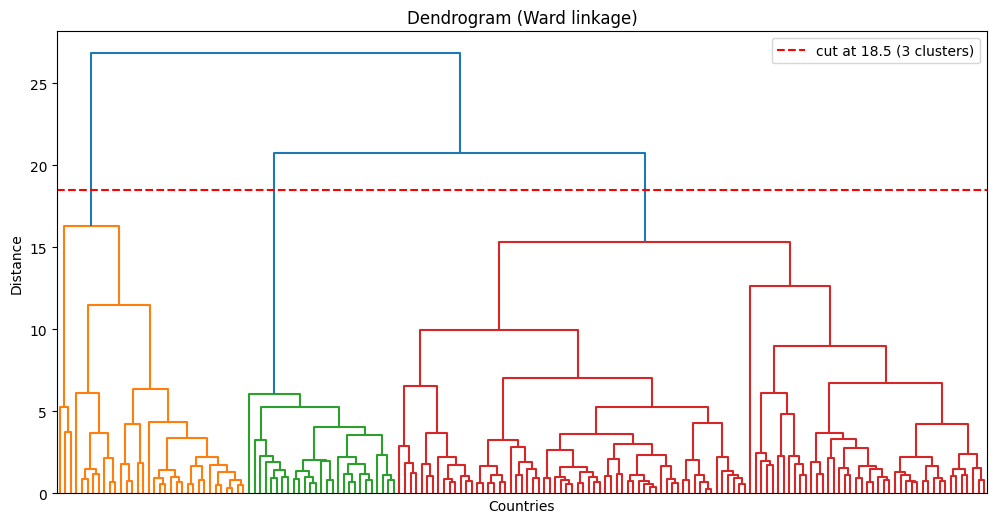

In [ ]:
linked = linkage(X_scaled, method="ward")

# Height that leaves exactly 3 clusters: halfway between the merge that leaves 3 clusters (linked[-3]) and the one that leaves 2 (linked[-2])
cut = (linked[-3, 2] + linked[-2, 2]) / 2

plt.figure(figsize=(12, 6))
dendrogram(linked, no_labels=True, color_threshold=cut)
plt.axhline(cut, color="red", linestyle="--", label=f"cut at {cut:.1f} (3 clusters)")
plt.title("Dendrogram (Ward linkage)")
plt.xlabel("Countries")
plt.ylabel("Distance")
plt.legend()
plt.show()

In [ ]:
linkage_methods = ["ward", "complete", "average", "single"]
results_h = []

for method in linkage_methods:
    for k in [2, 3, 4, 5]:
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X_scaled)
        results_h.append({"linkage": method, "clusters": k, "silhouette": round(silhouette_score(X_scaled, labels), 4), "cluster sizes": np.bincount(labels).tolist()})

pd.DataFrame(results_h)

,linkage,clusters,silhouette,cluster sizes
0,ward,2,0.3153,"[133, 34]"
1,ward,3,0.2456,"[34, 106, 27]"
2,ward,4,0.2481,"[106, 31, 27, 3]"
3,ward,5,0.2193,"[43, 31, 27, 3, 63]"
4,complete,2,0.2726,"[112, 55]"
5,complete,3,0.2901,"[55, 109, 3]"
6,complete,4,0.2864,"[109, 54, 3, 1]"
7,complete,5,0.2460,"[14, 95, 3, 1, 54]"
8,average,2,0.6303,"[166, 1]"
9,average,3,0.5620,"[163, 1, 3]"


In [ ]:
# Ward + 3 clusters: balanced cluster sizes (average/single put 166 countries in one cluster)
hierarchical = AgglomerativeClustering(n_clusters=3, linkage="ward")
hierarchical_labels = hierarchical.fit_predict(X_scaled)

df["Hierarchical_Cluster"] = hierarchical_labels
print(df["Hierarchical_Cluster"].value_counts().sort_index())

Hierarchical_Cluster
0     34
1    106
2     27
Name: count, dtype: int64


In [ ]:
hierarchical_score = silhouette_score(X_scaled, hierarchical_labels)
print("Hierarchical silhouette:", round(hierarchical_score, 4))
print("K-Means silhouette:", round(kmeans_score, 4))

Hierarchical silhouette: 0.2456
K-Means silhouette: 0.2833


In [ ]:
# added errors="ignore" to avoid crashes
df.groupby("Hierarchical_Cluster").mean(numeric_only=True).drop(columns=["KMeans_Cluster", "DBSCAN_Cluster"], errors="ignore").round(2)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
Hierarchical_Cluster,,,,,,,,,
0,5.96,58.51,8.50,48.90,47588.24,4.12,79.98,1.89,43170.59
1,31.62,39.99,6.35,48.09,11341.89,9.12,70.92,2.65,6407.37
2,105.07,23.59,6.51,39.66,1589.74,7.14,57.25,5.43,667.89


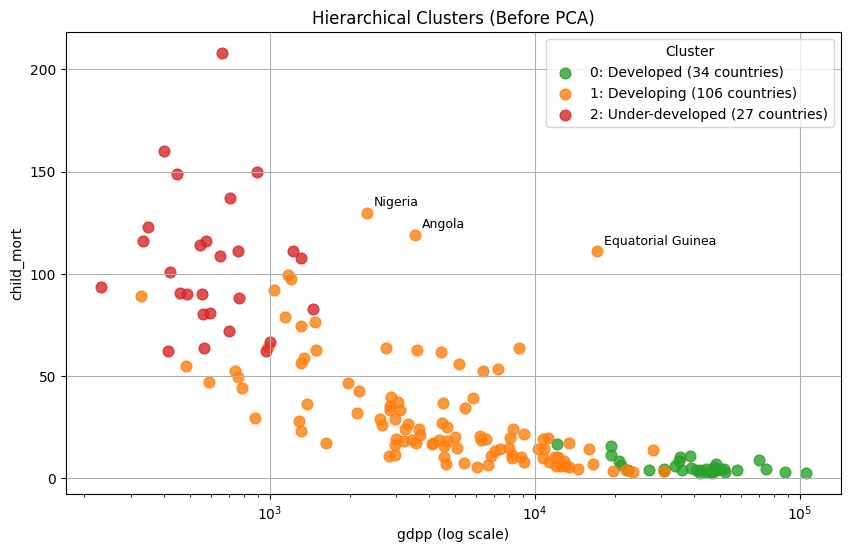

In [ ]:
hc_names  = {0: "Developed", 1: "Developing", 2: "Under-developed"}
colors = {0: "tab:green", 1: "tab:orange", 2: "tab:red"}

plt.figure(figsize=(10, 6))
for c in sorted(df["Hierarchical_Cluster"].unique()):
    sub = df[df["Hierarchical_Cluster"] == c]
    plt.scatter(sub["gdpp"], sub["child_mort"], s=60, alpha=0.8, color=colors[c], label=f"{c}: {hc_names[c]} ({len(sub)} countries)")

odd = df[(df["Hierarchical_Cluster"] == 1) & (df["child_mort"] > 100)] # Label the developing countries with unusually high child mortality
for _, row in odd.iterrows():
    plt.annotate(row["country"], (row["gdpp"], row["child_mort"]), fontsize=9, xytext=(5, 5), textcoords="offset points")

plt.xscale("log")
plt.title("Hierarchical Clusters (Before PCA)")
plt.xlabel("gdpp (log scale)")
plt.ylabel("child_mort")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

The clusters follow the expected curve: higher GDP per capita goes with lower child mortality. Some clusters overlap here because the clustering used all 9 features while this plot shows only 2. A few developing countries have very high child mortality despite moderate GDP (labeled on the plot), likely because other features such as exports, imports, or inflation placed them closer to the developing group. They're borderline cases between clusters.

In [ ]:
for c in sorted(df["Hierarchical_Cluster"].unique()):
    names = df[df["Hierarchical_Cluster"] == c]["country"].tolist()
    print("Cluster", c, "-", len(names), "countries")
    print(names)
    print()

Cluster 0 - 34 countries
['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Denmark', 'Finland', 'France', 'Germany', 'Greece', 'Iceland', 'Ireland', 'Israel', 'Italy', 'Japan', 'Kuwait', 'Libya', 'Luxembourg', 'Malta', 'Netherlands', 'New Zealand', 'Norway', 'Oman', 'Portugal', 'Qatar', 'Saudi Arabia', 'Singapore', 'Spain', 'Sweden', 'Switzerland', 'United Arab Emirates', 'United Kingdom', 'United States']

Cluster 1 - 106 countries
['Albania', 'Algeria', 'Angola', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Azerbaijan', 'Bahamas', 'Bangladesh', 'Barbados', 'Belarus', 'Belize', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Cambodia', 'Cape Verde', 'Chile', 'China', 'Colombia', 'Congo, Rep.', 'Costa Rica', 'Croatia', 'Cyprus', 'Czech Republic', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Estonia', 'Fiji', 'Gabon', 'Georgia', 'Ghana', 'Grenada', 'Guatemala', 'Guyana', 'Hungary', 'India

In [ ]:
pd.crosstab(df["Hierarchical_Cluster"], df["KMeans_Cluster"], rownames=["Hierarchical"], colnames=["K-Means"])

K-Means,0,1,2
Hierarchical,,,
0,31,0,3
1,5,20,81
2,0,27,0


In [ ]:
# K-Means label meanings, read from the crosstab above
km_names = {0: "Developed", 1: "Under-developed", 2: "Developing"}

hc_seg = df["Hierarchical_Cluster"].map(hc_names) # "hc_names" is from the scatter plot cell
km_seg = df["KMeans_Cluster"].map(km_names)

print(f"Agreement between Hierarchical and K-Means: {(hc_seg == km_seg).mean():.1%}")

disagree = df.loc[hc_seg != km_seg, ["country"]].assign(Hierarchical=hc_seg, KMeans=km_seg)
disagree.sort_values(["Hierarchical", "KMeans"])

Agreement between Hierarchical and K-Means: 83.2%


,country,Hierarchical,KMeans
89,Libya,Developed,Developing
115,Oman,Developed,Developing
128,Saudi Arabia,Developed,Developing
42,Cyprus,Developing,Developed
43,Czech Republic,Developing,Developed
134,Slovak Republic,Developing,Developed
135,Slovenia,Developing,Developed
138,South Korea,Developing,Developed
3,Angola,Developing,Under-developed
21,Botswana,Developing,Under-developed


In [ ]:
from sklearn.metrics import adjusted_rand_score

rng = np.random.default_rng(42)
stability = []
for method in linkage_methods:
    base = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(X_scaled)
    aris = []
    for _ in range(20):
        X_noisy = X_scaled + rng.normal(0, 0.05, X_scaled.shape)   # noise = 5% of each feature's std
        noisy = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(X_noisy)
        aris.append(adjusted_rand_score(base, noisy))
    stability.append({"linkage": method,
                      "mean_ARI": round(np.mean(aris), 3),
                      "std_ARI": round(np.std(aris), 3)})
pd.DataFrame(stability)

,linkage,mean_ARI,std_ARI
0,ward,0.536,0.123
1,complete,0.257,0.286
2,average,0.961,0.060
3,single,0.983,0.075


### Hierarchical Clustering Findings

**Best settings:** Ward linkage, 3 clusters (dendrogram cut at 18.5).

**Why Ward:** Average and single linkage had the highest silhouette scores (up to 0.63), but only by isolating outliers (166 countries in one cluster, 1 in the other). Complete linkage scored 0.29, but one of its 3 clusters had only 3 countries. Ward was the only method with three balanced, meaningful clusters. A high silhouette can come from isolating a few extreme countries, so cluster sizes must be checked too.

**Why 3 clusters:** k = 2 scored higher (0.315) but only separates the 34 rich countries from the rest. k = 4 scored about the same as k = 3 (0.248 vs 0.246) only by splitting 3 countries off the rich cluster. The dendrogram shows a wide gap for 3 clusters (any cut between ~16.3 and ~20.8).

**Results** (silhouette 0.2456 vs 0.2833 for K-Means):

| Cluster | Countries | Child mortality | Income | Life expectancy | Fertility | Examples |
|---|---|---|---|---|---|---|
| 0: Developed | 34 | ~6 | ~47,600 | ~80 | ~1.9 | Australia, Germany, Canada |
| 1: Developing | 106 | ~32 | ~11,300 | ~71 | ~2.7 | |
| 2: Under-developed | 27 | ~105 | ~1,600 | ~57 | ~5.4 | Afghanistan, Chad, Burundi |

**What we found out:**
- **Same levels, different borders:** Hierarchical and K-Means agree on 83% of countries and never disagree by more than one level. All 28 disagreements are borderline cases:
  - At the top, Hierarchical puts oil states (Saudi Arabia, Oman, Libya) in Developed, while K-Means puts advanced non-oil economies (South Korea, Czech Republic, Slovenia) there instead.
  - At the bottom, K-Means labels 20 more countries Under-developed, including oil exporters (Nigeria, Angola, Equatorial Guinea) and Southern African and conflict-affected countries. If aid were based on this cluster, the algorithm choice would change the outcome for these 20 countries.
- **No natural groups:** both silhouette scores are low (~0.25 and ~0.28). Countries lie on a continuous range from poor to rich, so each algorithm cuts that range in slightly different places. The broad Developing cluster (from South Korea to Yemen) reflects this.
- **Sensitivity to noise:** every country is forced into a cluster (no noise label). With 5% random noise added, Ward kept a mean ARI of 0.54: the overall structure stays the same, but borderline countries move. Single and average linkage looked more stable (~0.96–0.98) only because they keep isolating the same outliers.

**Conclusion:** Hierarchical clustering finds the same rich / middle / poor structure as K-Means and is easy to explain with the dendrogram, but K-Means scored slightly better on this dataset.

## PCA

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.metrics.cluster import contingency_matrix
from scipy.optimize import linear_sum_assignment

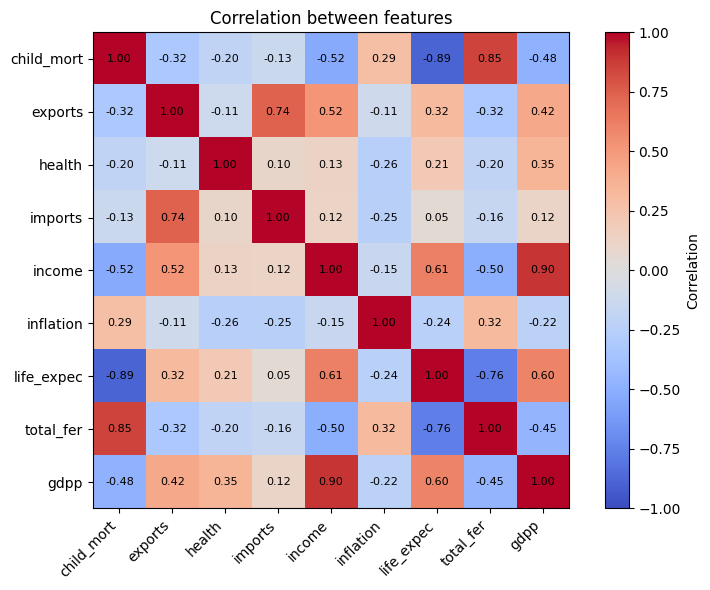

In [ ]:
corr = X.corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation between features")
plt.tight_layout()
plt.show()

In [ ]:
# Fit PCA with ALL components to see how much variance each one explains
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
eigenvalues = explained * X_scaled.shape[1]   # Kaiser criterion: eigenvalue > 1

variance_table = pd.DataFrame({
    "Explained": explained,
    "Cumulative": cumulative,
    "Eigenvalue": eigenvalues
}, index=[f"PC{i}" for i in range(1, len(explained) + 1)])
print(variance_table.round(4))


     Explained  Cumulative  Eigenvalue
PC1     0.4595      0.4595      4.1357
PC2     0.1718      0.6313      1.5463
PC3     0.1300      0.7614      1.1704
PC4     0.1105      0.8719      0.9948
PC5     0.0734      0.9453      0.6606
PC6     0.0248      0.9702      0.2236
PC7     0.0126      0.9828      0.1134
PC8     0.0098      0.9926      0.0883
PC9     0.0074      1.0000      0.0669


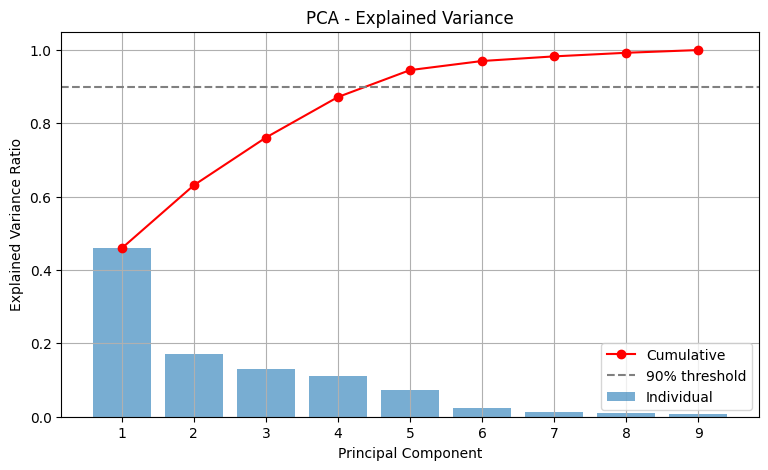

In [ ]:
components = range(1, len(explained) + 1)

plt.figure(figsize=(9, 5))
plt.bar(components, explained, alpha=0.6, label="Individual")
plt.plot(components, cumulative, marker="o", color="red", label="Cumulative")
plt.axhline(0.90, color="gray", linestyle="--", label="90% threshold")
plt.title("PCA - Explained Variance")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
pca2 = PCA(n_components=2, random_state=42)
X_pca2 = pca2.fit_transform(X_scaled)

print("Original features:", X_scaled.shape[1], "-> Components:", X_pca2.shape[1])
print("Variance explained by PC1:", round(pca2.explained_variance_ratio_[0], 4))
print("Variance explained by PC2:", round(pca2.explained_variance_ratio_[1], 4))
print("Total variance kept:", round(pca2.explained_variance_ratio_.sum(), 4))

loadings2 = pd.DataFrame(pca2.components_.T, columns=["PC1", "PC2"], index=X.columns)
loadings2.round(3)

Original features: 9 -> Components: 2
Variance explained by PC1: 0.4595
Variance explained by PC2: 0.1718
Total variance kept: 0.6313


,PC1,PC2
child_mort,-0.420,0.193
exports,0.284,0.613
health,0.151,-0.243
imports,0.161,0.672
income,0.398,0.023
inflation,-0.193,-0.008
life_expec,0.426,-0.223
total_fer,-0.404,0.155
gdpp,0.393,-0.046


## K-Means (After PCA)

In [ ]:
km_pca2 = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels_pca2 = km_pca2.fit_predict(X_pca2)

cm = contingency_matrix(kmeans_labels, labels_pca2)
rows, cols = linear_sum_assignment(-cm)
mapping = {c: r for r, c in zip(rows, cols)}
labels_pca2_aligned = np.array([mapping[l] for l in labels_pca2])

sil_before = silhouette_score(X_scaled, kmeans_labels)
sil_after_own = silhouette_score(X_pca2, labels_pca2)
sil_after_orig = silhouette_score(X_scaled, labels_pca2)
ari = adjusted_rand_score(kmeans_labels, labels_pca2)
n_changed = int((kmeans_labels != labels_pca2_aligned).sum())

print("Cluster sizes after PCA:", np.bincount(labels_pca2_aligned))
print("Silhouette before PCA (original space):      ", round(sil_before, 4))
print("Silhouette after PCA (PCA space):            ", round(sil_after_own, 4))
print("Silhouette after PCA (original scaled space):", round(sil_after_orig, 4))
print("Adjusted Rand Index:", round(ari, 4))
print("Countries that changed cluster:", n_changed, "out of", len(df))

Cluster sizes after PCA: [ 3 72 92]
Silhouette before PCA (original space):       0.2833
Silhouette after PCA (PCA space):             0.4416
Silhouette after PCA (original scaled space): 0.2951
Adjusted Rand Index: 0.3178
Countries that changed cluster: 58 out of 167


## Comparison

In [ ]:
# Comparing the 3 algorithms
algo_comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN", "Hierarchical"],
    "Clusters": [len(set(kmeans_labels)), len(set(dbscan_labels)) - 1, len(set(hierarchical_labels))],
    "Noise points": [0, (dbscan_labels == -1).sum(), 0],
    "Smallest cluster": [np.bincount(kmeans_labels).min(), np.bincount(dbscan_labels[dbscan_labels != -1]).min(), np.bincount(hierarchical_labels).min()],
    "Largest cluster": [np.bincount(kmeans_labels).max(), np.bincount(dbscan_labels[dbscan_labels != -1]).max(), np.bincount(hierarchical_labels).max()],
    "Silhouette": [round(kmeans_score, 4), round(dbscan_score, 4), round(hierarchical_score, 4)],
})
algo_comparison

,Algorithm,Clusters,Noise points,Smallest cluster,Largest cluster,Silhouette
0,K-Means,3,0,36,84,0.2833
1,DBSCAN,2,48,24,95,0.4131
2,Hierarchical,3,0,27,106,0.2456


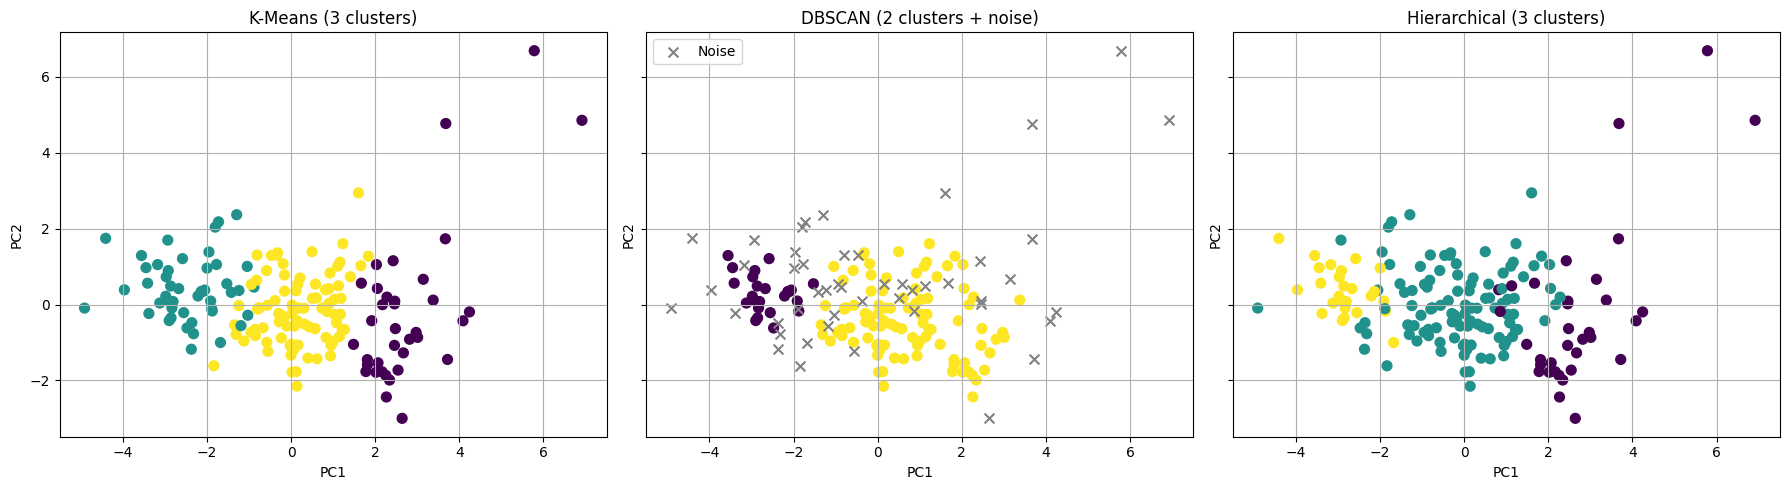

In [ ]:
# The 3 algorithms side by side on PC1 vs PC2
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=kmeans_labels, cmap="viridis", s=50)
axes[0].set_title("K-Means (3 clusters)")

noise = dbscan_labels == -1
axes[1].scatter(X_pca2[~noise, 0], X_pca2[~noise, 1], c=dbscan_labels[~noise], cmap="viridis", s=50)
axes[1].scatter(X_pca2[noise, 0], X_pca2[noise, 1], c="gray", marker="x", s=50, label="Noise")
axes[1].set_title("DBSCAN (2 clusters + noise)")
axes[1].legend()

axes[2].scatter(X_pca2[:, 0], X_pca2[:, 1], c=hierarchical_labels, cmap="viridis", s=50)
axes[2].set_title("Hierarchical (3 clusters)")

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(True)

plt.tight_layout()
plt.show()

### K-Means: Before vs After PCA

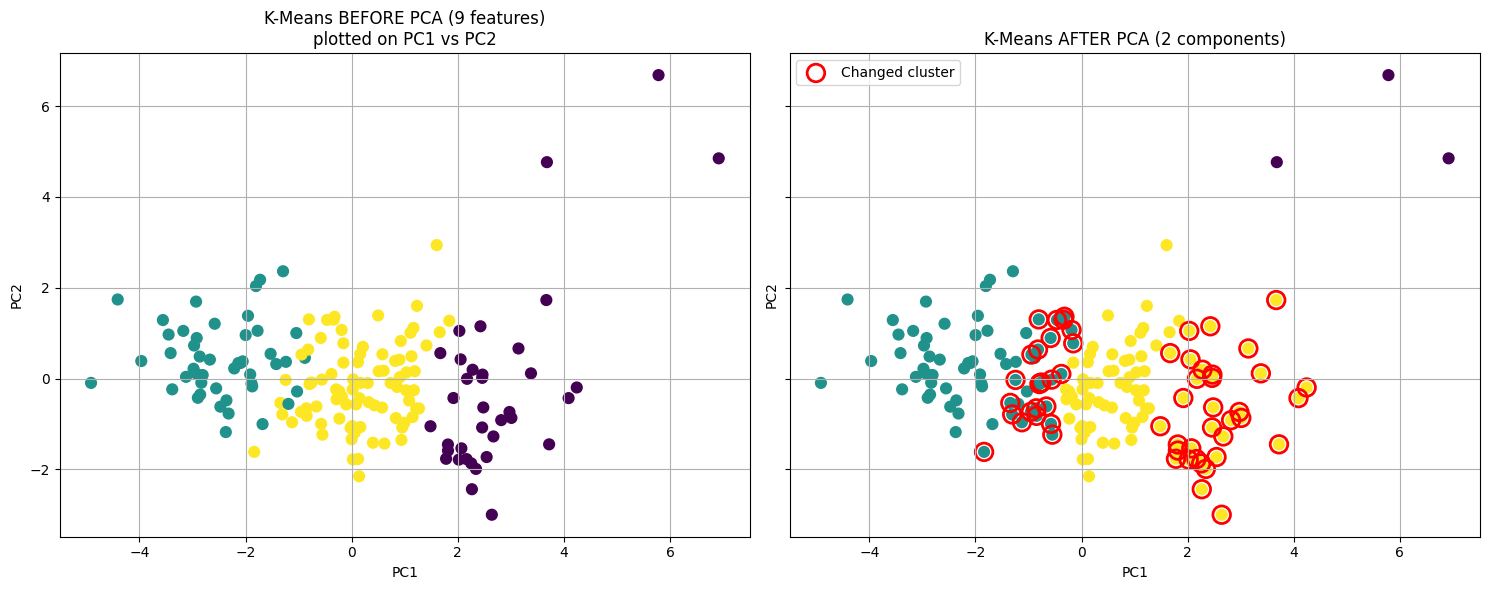

In [ ]:
changed = kmeans_labels != labels_pca2_aligned

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=kmeans_labels, cmap="viridis", s=60)
axes[0].set_title("K-Means BEFORE PCA (9 features)\nplotted on PC1 vs PC2")

axes[1].scatter(X_pca2[:, 0], X_pca2[:, 1], c=labels_pca2_aligned, cmap="viridis", s=60)
axes[1].scatter(X_pca2[changed, 0], X_pca2[changed, 1], facecolors="none",
                edgecolors="red", s=160, linewidths=2, label="Changed cluster")
axes[1].set_title("K-Means AFTER PCA (2 components)")
if changed.any():
    axes[1].legend()

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
df["KMeans_PCA2_Cluster"] = labels_pca2_aligned
drop_cols = [c for c in ["KMeans_Cluster", "KMeans_PCA_Cluster", "DBSCAN_Cluster", "Hierarchical_Cluster"] if c in df.columns]
df.groupby("KMeans_PCA2_Cluster").mean(numeric_only=True).drop(columns=drop_cols).round(2)

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
KMeans_PCA2_Cluster,,,,,,,,,
0,4.13,176.00,6.79,156.67,64033.33,2.47,81.43,1.38,57566.67
1,73.36,30.58,6.00,43.70,4531.85,11.58,62.46,4.30,2178.67
2,11.92,44.95,7.45,45.80,25486.63,4.98,76.54,1.94,19950.54


In [ ]:
small = df.groupby("KMeans_PCA2_Cluster").size().idxmin()
df[df["KMeans_PCA2_Cluster"] == small]["country"].tolist()

['Luxembourg', 'Malta', 'Singapore']

In [ ]:
# ===== ALL CLUSTERS BEFORE PCA =====
print("=" * 70)
print("K-MEANS BEFORE PCA (9 features)")
print("=" * 70)
for c in range(best_k):
    names = sorted(df[df["KMeans_Cluster"] == c]["country"].tolist())
    print(f"\nCluster {c} ({len(names)} countries):")
    print(", ".join(names))

# ===== ALL CLUSTERS AFTER PCA =====
print("\n\n" + "=" * 70)
print("K-MEANS AFTER PCA (2 components)")
print("=" * 70)
for c in range(best_k):
    names = sorted(df[df["KMeans_PCA2_Cluster"] == c]["country"].tolist())
    print(f"\nCluster {c} ({len(names)} countries):")
    print(", ".join(names))

K-MEANS BEFORE PCA (9 features)

Cluster 0 (36 countries):
Australia, Austria, Bahrain, Belgium, Brunei, Canada, Cyprus, Czech Republic, Denmark, Finland, France, Germany, Greece, Iceland, Ireland, Israel, Italy, Japan, Kuwait, Luxembourg, Malta, Netherlands, New Zealand, Norway, Portugal, Qatar, Singapore, Slovak Republic, Slovenia, South Korea, Spain, Sweden, Switzerland, United Arab Emirates, United Kingdom, United States

Cluster 1 (47 countries):
Afghanistan, Angola, Benin, Botswana, Burkina Faso, Burundi, Cameroon, Central African Republic, Chad, Comoros, Congo, Dem. Rep., Congo, Rep., Cote d'Ivoire, Equatorial Guinea, Eritrea, Gabon, Gambia, Ghana, Guinea, Guinea-Bissau, Haiti, Iraq, Kenya, Kiribati, Lao, Lesotho, Liberia, Madagascar, Malawi, Mali, Mauritania, Mozambique, Namibia, Niger, Nigeria, Pakistan, Rwanda, Senegal, Sierra Leone, South Africa, Sudan, Tanzania, Timor-Leste, Togo, Uganda, Yemen, Zambia

Cluster 2 (84 countries):
Albania, Algeria, Antigua and Barbuda, Argent

In [ ]:
comparison = pd.DataFrame({
    "Metric": ["Number of features", "Variance kept",
               "Silhouette (own space)", "Silhouette (original scaled space)",
               "Countries that changed cluster"],
    "Before PCA": [X_scaled.shape[1], 1.0, round(sil_before, 4), round(sil_before, 4), 0],
    "After PCA (2 PCs)": [2, round(pca2.explained_variance_ratio_.sum(), 4),
                          round(sil_after_own, 4), round(sil_after_orig, 4), n_changed],
})
print(comparison.to_string(index=False))
print("\nAdjusted Rand Index:", round(ari, 4))
print("Note: Inertia and 'own-space' silhouette are not comparable across different spaces.")

                            Metric  Before PCA  After PCA (2 PCs)
                Number of features      9.0000             2.0000
                     Variance kept      1.0000             0.6313
            Silhouette (own space)      0.2833             0.4416
Silhouette (original scaled space)      0.2833             0.2951
    Countries that changed cluster      0.0000            58.0000

Adjusted Rand Index: 0.3178
Note: Inertia and 'own-space' silhouette are not comparable across different spaces.


In [ ]:
rows_out = []
for n in range(2, X_scaled.shape[1] + 1):
    p = PCA(n_components=n, random_state=42)
    Xp = p.fit_transform(X_scaled)
    lab = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(Xp)
    rows_out.append({
        "PCs": n,
        "Variance kept": round(p.explained_variance_ratio_.sum(), 4),
        "Silhouette (original space)": round(silhouette_score(X_scaled, lab), 4),
        "ARI vs before PCA": round(adjusted_rand_score(kmeans_labels, lab), 4),
    })

pd.DataFrame(rows_out)

,PCs,Variance kept,Silhouette (original space),ARI vs before PCA
0,2,0.6313,0.2951,0.3178
1,3,0.7614,0.2970,0.3334
2,4,0.8719,0.2849,0.9618
3,5,0.9453,0.2833,1.0000
4,6,0.9702,0.2833,1.0000
5,7,0.9828,0.2833,1.0000
6,8,0.9926,0.2833,1.0000
7,9,1.0000,0.2833,1.0000


In [ ]:
print("KEY NUMBERS")
print("- Features: 9 -> 2")
print("- Variance kept with 2 PCs:", round(pca2.explained_variance_ratio_.sum(), 4))
print("- ARI (before vs after):", round(ari, 4))
print("- Countries that changed cluster:", n_changed, "of", len(df))
print("- Silhouette in original space: before =", round(sil_before, 4),
      "| after =", round(sil_after_orig, 4))

KEY NUMBERS
- Features: 9 -> 2
- Variance kept with 2 PCs: 0.6313
- ARI (before vs after): 0.3178
- Countries that changed cluster: 58 of 167
- Silhouette in original space: before = 0.2833 | after = 0.2951


## Critical Thinking

**Which algorithm performed best? Why?**

**K-Means**, because it had the highest silhouette (0.2833) among the algorithms that place all 167 countries, and it gave 3 clear groups: rich, middle-income and poor. Hierarchical gave similar groups but scored lower (0.2456). DBSCAN scored 0.4131, but only after removing 48 countries as noise, so its score is not a fair comparison.

**When would you use each algorithm?**

- **K-Means:** when you know (or can estimate) the number of clusters and the groups are roughly round and similar in size.
- **DBSCAN:** when clusters have irregular shapes, or when you want to find outliers, and the data has clear dense areas separated by empty space.
- **Hierarchical:** when you don't know the number of clusters and want to see how groups merge step by step in a dendrogram. Best for small datasets.

**What are the strengths and weaknesses of each?**

| | Strengths | Weaknesses |
|---|---|---|
| **K-Means** | Fast, simple, easy to explain | You must choose K, it assumes round clusters, and outliers are forced into a cluster and pull the centers |
| **DBSCAN** | No need to choose K, finds any shape, detects outliers | Very sensitive to eps and min_samples, and fails when density is uneven (like this data: 1 cluster or 29% noise) |
| **Hierarchical** | Dendrogram shows the structure, no need to guess K in advance | Slow on large data, a merge cannot be undone, and outliers are forced into a cluster (like K-Means) |

---
**PCA:**

**How did PCA affect the clustering results?**

Two components keep 63.1% of the variance. The clustering changed noticeably: ARI = 0.32, and 58 of 167 countries moved to a different cluster. Cluster sizes went from 36 / 47 / 84 to 3 / 72 / 92, because PC2 (driven by exports and imports) isolated 3 countries with extreme trade volume.

**Did the visualization become clearer?**

Yes. All countries can be shown in one 2D plot, where PC1 reflects development level and PC2 reflects trade volume. But the plot shows only 63% of the information.

**Did you lose important information?**

Yes. 36.9% of the variance was discarded, and this changed the cluster structure, so the lost components mattered for clustering.

**Which approach is better and why?**

The original 9 features give a more faithful and balanced clustering. PCA with 2 components is better for visualization only. Silhouette in the original space is almost the same (0.2951 vs 0.2833), so PCA did not improve quality. The value 0.4416 is computed in a different space and inflated by the small cluster, so it is not comparable.

## Final Summary

- We clustered 167 countries using 9 economic and health features after scaling.
- **K-Means (K = 3)** performed best: silhouette 0.2833, with clear rich (36), middle (84) and poor (47) groups.
- **Hierarchical (Ward, 3 clusters)** found the same 3 levels with different borders (34 / 106 / 27) and a lower silhouette (0.2456).
- **DBSCAN** did not split the data well. The countries change gradually from poor to rich with no empty gaps, so it gave either 1 cluster or 2 clusters with 29% noise. Its real value here was **finding outliers** like Luxembourg, Singapore, Qatar and Nigeria.
- **PCA** with 2 components kept 63% of the variance. It made visualization easy, but changed 58 countries' clusters, so it is better for plotting than for clustering.
- **Key insight:** this dataset has no natural, well-separated groups. The clusters are useful levels of development, not sharply different groups, which is why all silhouette scores are low (under 0.3 for full clustering).